# **CS 5361/6361 Machine Learning**

**Linear and Logistic Regression with Tensorflow**

**Author:** [Olac Fuentes](http://www.cs.utep.edu/ofuentes/)<br>
**Last modified:** 4/6/2026<br>

The tensorflow library allows flexible and very efficient implementations of models consisting of sequences of linear operations (matrix multiplication) and non-linear operations (such as sigmoid). Gradient computations are performed automatically and several optimization algorithms are provided to optimize model parameters. Several loss functions (such as mean squared error, mean absolute error, and cross entropy) are also provided.

In this notebook we will see how to implement linear and logistic regression with tensorflow using the sequential model class, which allows to easily define sequences of operations that extract an output from an input.

Import libraries

In [ ]:
import tensorflow as tf
import numpy as np
import os
import distutils
import matplotlib.pyplot as plt
from keras.models import Model
from tensorflow.keras.layers import *
from tensorflow.keras.activations import *
from keras.utils import plot_model
from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error
import time

Function to plot loss and accuracy of the models during training.

In [ ]:
def plot_results(history):
  fig, ax = plt.subplots(ncols=2, figsize=(12,4))
  ax[0].plot(history.history['accuracy'],label = 'train')
  ax[0].plot(history.history['val_accuracy'],label = 'test')
  ax[0].set_title('Accuracy')
  ax[0].legend(loc='lower right')
  ax[0].grid(True)
  ax[1].plot(history.history['loss'],label = 'train')
  ax[1].plot(history.history['val_loss'],label = 'test')
  ax[1].set_title('Loss')
  ax[1].legend(loc='upper right')
  ax[1].grid(True)
  plt.show()

Load, scale and reshape the data.

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = np.float32(x_train/255).reshape(x_train.shape[0],-1)
x_test = np.float32(x_test/255).reshape(x_test.shape[0],-1)

# Convert y to one-hot
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


# **Linear Regression**

Model definition

In [ ]:
def linear_regression(n_inputs=784, n_outputs=10):
  # Define a sequential model, initially containing no operations
  model = tf.keras.models.Sequential()
  # Add an input layer, which specifies the dimensionality of the input data
  model.add(Input((n_inputs,)))
  # Add a dense layer, which implements the function y = np.matmul(X*W) + b
  # The number number of inputs is the number of outputs of the previous layer
  # and the number number of outputs is provided as a parameter
  model.add(Dense(n_outputs))    # In the example, W is 784-by-10, and b is (10,)
  return model

Model creation

In [ ]:
model = linear_regression(x_train.shape[1], y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(optimizer=tf.keras.optimizers.Adam(),  loss="mse", metrics=["accuracy"])               # Specify optimizer (optional) and loss function

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

We can show a graphical representation of the operations to be performed by the model. In this case we have a single layer with 784 inputs and 10 outputs.

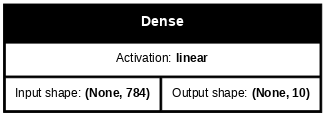

In [ ]:
plot_model(model, show_shapes=True, show_layer_names=False, show_layer_activations=True, dpi=64) # Graphical depiction of mode

Training the model. As with Sklearn, the fit function finds the parameters of the model that best fit the training data. Optionally, we can evaluate performance on the test (or validation) data as we train.

Results are similar to those of the Sklearn implementation.

Epoch 1/40
60/60 - 5s - 83ms/step - accuracy: 0.5287 - loss: 0.1026 - val_accuracy: 0.7546 - val_loss: 0.0611
Epoch 2/40
60/60 - 0s - 4ms/step - accuracy: 0.7814 - loss: 0.0553 - val_accuracy: 0.8176 - val_loss: 0.0496
Epoch 3/40
60/60 - 0s - 4ms/step - accuracy: 0.8174 - loss: 0.0482 - val_accuracy: 0.8311 - val_loss: 0.0456
Epoch 4/40
60/60 - 0s - 4ms/step - accuracy: 0.8299 - loss: 0.0451 - val_accuracy: 0.8407 - val_loss: 0.0435
Epoch 5/40
60/60 - 0s - 4ms/step - accuracy: 0.8376 - loss: 0.0434 - val_accuracy: 0.8485 - val_loss: 0.0423
Epoch 6/40
60/60 - 0s - 4ms/step - accuracy: 0.8421 - loss: 0.0422 - val_accuracy: 0.8443 - val_loss: 0.0415
Epoch 7/40
60/60 - 0s - 4ms/step - accuracy: 0.8450 - loss: 0.0414 - val_accuracy: 0.8511 - val_loss: 0.0409
Epoch 8/40
60/60 - 0s - 4ms/step - accuracy: 0.8472 - loss: 0.0408 - val_accuracy: 0.8548 - val_loss: 0.0403
Epoch 9/40
60/60 - 0s - 4ms/step - accuracy: 0.8485 - loss: 0.0404 - val_accuracy: 0.8530 - val_loss: 0.0399
Epoch 10/40
60/60 

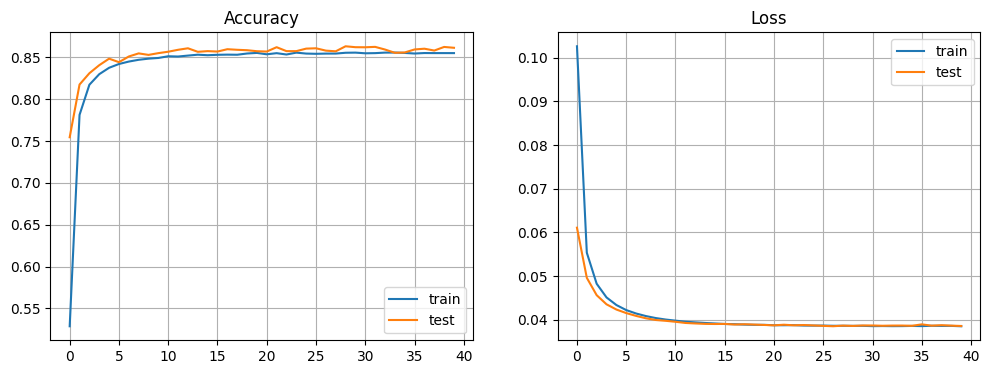

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Elapsed time training= 15.6529 secs
Accuracy = 0.8615
Confusion matrix
[[ 942    0    1    2    2    9   14    2    7    1]
 [   0 1101    3    3    2    1    5    0   20    0]
 [  17   55  812   26   11    1   39   21   42    8]
 [   4   16   28  873    5   20    7   21   24   12]
 [   0   22    6    0  876    5   11    2   13   47]
 [  19   18    2   56   22  683   19   14   43   16]
 [  16   10   10    0   23   24  867    0    8    0]
 [   4   42   17    5   26    1    1  874    0   58]
 [  14   48   10   23   25   39   15   10  769   21]
 [  14   11    1   16   72    3    1   67    6  818]]


In [ ]:
start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs =40, # Perform 10 iterations over the whole dataset
    batch_size = 1000, # Split training data into groups of size 1000
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))


# **Logistic Regression**

We can add the softmax operation as an additional layer in the model.

In [ ]:
def logistic_regression(n_inputs, n_outputs):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(n_outputs))
  model.add(Softmax())
  # The dense and softmax operations can be combined into a single layer
  # model.add(Dense(n_outputs,activation = "softmax"))
  return model

Typically, we use the categorical cross entropy loss function, instead of mean-squared error.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 10)             │         7,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

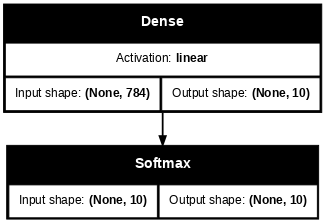

In [ ]:
model = logistic_regression(x_train.shape[1], y_train.shape[1])
model.summary()
model.compile(optimizer=tf.keras.optimizers.Adam(), loss="CategoricalCrossentropy", metrics=["accuracy"])
plot_model(model, show_shapes=True, show_layer_names=False, show_layer_activations=True, dpi=64)

We will now fit the model. Again, results are similar to those obtained by Sklearn.

Epoch 1/40
60/60 - 5s - 79ms/step - accuracy: 0.5973 - loss: 1.4708 - val_accuracy: 0.8037 - val_loss: 0.9048
Epoch 2/40
60/60 - 0s - 5ms/step - accuracy: 0.8310 - loss: 0.7532 - val_accuracy: 0.8666 - val_loss: 0.6108
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.8644 - loss: 0.5708 - val_accuracy: 0.8855 - val_loss: 0.5002
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.8795 - loss: 0.4882 - val_accuracy: 0.8948 - val_loss: 0.4412
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.8884 - loss: 0.4401 - val_accuracy: 0.9013 - val_loss: 0.4047
Epoch 6/40
60/60 - 0s - 4ms/step - accuracy: 0.8946 - loss: 0.4082 - val_accuracy: 0.9051 - val_loss: 0.3788
Epoch 7/40
60/60 - 0s - 4ms/step - accuracy: 0.8997 - loss: 0.3852 - val_accuracy: 0.9063 - val_loss: 0.3612
Epoch 8/40
60/60 - 0s - 4ms/step - accuracy: 0.9032 - loss: 0.3679 - val_accuracy: 0.9082 - val_loss: 0.3462
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.9054 - loss: 0.3546 - val_accuracy: 0.9094 - val_loss: 0.3356
Epoch 10/40
60/60 

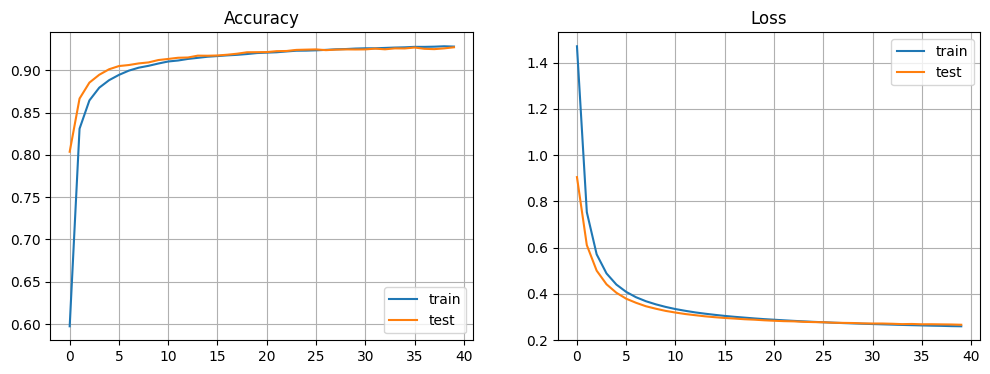

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 15.5562 secs
Accuracy = 0.9273
Confusion matrix
[[ 956    0    2    1    0    5    9    4    3    0]
 [   0 1109    3    2    1    2    4    2   12    0]
 [   4    9  932   14    8    3   12    9   37    4]
 [   2    0   22  921    1   23    2    8   22    9]
 [   1    1    5    0  913    0   13    4    9   36]
 [   8    2    5   29   10  780   14    8   29    7]
 [  10    3    7    1    7   11  916    2    1    0]
 [   1    6   24    5    7    0    0  946    3   36]
 [   7    6    7   17    9   21   11   11  878    7]
 [  10    6    2   10   27    6    0   20    6  922]]


In [ ]:
start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40,
    batch_size = 1000,
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))

# **Exercises**

## Exercise 1.

Evaluate the performance of linear regression with the addition of another dense layer after the input. You can select any number of output units; it be reasonable to choose a number between 10 and 784. Does the addition of a layer improve performance? Why?

## Exercise 2.

Evaluate the performance of logistic regression with the addition of another dense layer after the input. You can select any number of output units; it be reasonable to choose a number between 10 and 784. Does the addition of a layer improve performance? Why?